<a href="https://colab.research.google.com/github/CookOLo/MAT422/blob/main/HW_3_7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 3.7 - Nueral Networks
**Artificial neural networks**: a collection of connected layers of units or nodes to loosely model the neurons in a biological brain

## 3.7.1 - Mathematical formulation

Activation function $σ (z)$ that changes the a neural network in advance:
- $\hat{y}$: forcast output
- $x_i$: inputs
- $w_i$: weights
- $b$: bias

$$\hat{y} = σ(z) = σ(w_1a_1 + w_2a_2 + b), a_1 = x_1, a_2 = x_2$$

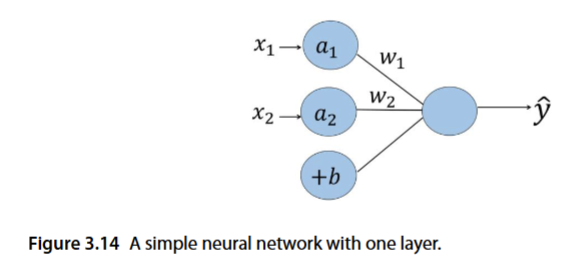

- a general network may have hundreds or thousands of nodes
- input units receive various forms and structures of info based on an internal weighting system --> network adjusts its weighted associated according to a learning rule and using error value --> successive adjustments are made to be increasingly similar to target output

Mathematical notation for a neural network:
- $l$: layers
- $j$: left-handed node
- $j'$: right-handed node
- $J_I$: number of nodes in layer $l$

$$z_j^{(l)} = \sum_{j'=1}^{J_{l-1}} w_{j,j'}^{(l)} a_{j'}^{(l-1)} + b_j^{(l)}
$$

For a given activation function, $\sigma$, we end up with the following expression for the values in the next layer:


$$a_j^{(l)} = \sigma\left(z_j^{(l)}\right)$$


In [7]:
import numpy as np
import matplotlib.pyplot as plt
import numpy as np
import sklearn

In [8]:
# Test Data
X = np.array([[0, 1], [1, 1], [1, 0], [1, -1]])
y = np.array([0, 1, 1, 0])

# Setting up weights and biases -- random
def initialize_parameters(layer_dim):     # layer dim is ([input nodes], [layer], [output nodes])
    np.random.seed(100)
    parameters = {}
    Length = len(layer_dim)

    for i in range(1,Length):
        parameters['w'+str(i)]=np.random.rand(layer_dim[i],layer_dim[i-1])*0.1
        parameters['b'+str(i)]=np.zeros((layer_dim[i],1))

    return parameters

# Setting up Sigmoid
def sigmoid(input):
  return 1 / (1 + np.exp(-input))

###### Activation Function #####
def activationFunction(x, w, b, activation=sigmoid):
    # a1 = x1, a2 = x2, so the inputs are used directly as activations
    a = x
    z = np.dot(w, a) + b          # z = w1*a1 + w2*a2 + b
    y_hat = activation(z)         # y_hat = sigma(z)
    return y_hat

# Example values
x = np.array([0.5, 1.0])   # x1, x2
w = np.array([0.4, -0.6])  # w1, w2
b = 0.1

###### Testing Activation Function #########
y_hat = activationFunction(X[1], w, b)
print(f"z = {np.dot(w, x) + b:.4f}")
print(f"y_hat = {y_hat:.4f}")

z = -0.3000
y_hat = 0.4750


In [29]:
#### Neural Network based on matrix formulation ####
def layer_z(W, b, a_prev):
    return W @ a_prev + b

#### Testing ####
parameters = initialize_parameters([2, 1, 1])
x = np.array([[0.5], [0.8]])          # a^(0), the inputs

z1 = layer_z(parameters['w1'], parameters['b1'], x)
a1 = 1 / (1 + np.exp(-z1))            # a^(1) = sigma(z^(1))

print("Z =", z1);

Z = [[0.0494398]]


## 3.7.2 - Activation functions
$\sigma$ is used to represent the activation functions, but there are many:

### 3.7.2.1 - Step function
**Heaviside step function/unit step function**: represents a signal that switches on at a specified time and stays switched on indefinite

$$\sigma(x) = \begin{cases}
0, & x < 0, \\
1, & x \geq 0.
\end{cases}$$

### 3.7.2.2 0 ReLU function

**positive linear/ReLU function**: signal either passes through untouched or dies completely
- enable better training of deeper networks compared to the widely used activation functions
- most commonly used activation function

$$\sigma(x) = max(0, x)$$

In [27]:
def relu(x):
    return(np.maximum(0,x))

## Testing ##
x = np.array([-3.0, -1.0, -0.5, 0.0, 0.5, 2.0])
print("ReLU function: ")
print("Test data =", x)
print("sigma =", relu(x))

ReLU function: 
Test data = [-3.  -1.  -0.5  0.   0.5  2. ]
sigma = [0.  0.  0.  0.  0.5 2. ]


### 3.7.2.3 - Sigmoid

**Sigmoid/logistic function**: can be used in the output layer for predicting probability

$$\sigma(x) = \frac{1}{1 + e^{-x}}$$

In [30]:
# Setting up Sigmoid -- repeated for showcase
def sigmoid(input):
  return 1 / (1 + np.exp(-input))

  ## Testing ##
x = np.array([-3.0, -1.0, -0.5, 0.0, 0.5, 2.0])
print("Sigmoid function: ")
print("Test data =", x)
print("sigma =", sigmoid(x))

Sigmoid function: 
Test data = [-3.  -1.  -0.5  0.   0.5  2. ]
sigma = [0.04742587 0.26894142 0.37754067 0.5        0.62245933 0.88079708]


### 3.7.2.4 - Softmax function

**softmax function**: converts a vector of numbers (an array of $K$ values ($z)) into a vector of probabilities, where the probabilities of each value are proportional to the relative scale of each value in the vector
- often used in the final, output layer of a neural netowrk, especially with classificaiton problems

$$\frac{e^{z_k}}{\sum_{k=1}^{K} e^{z_k}}$$

In [32]:
def softmax(x):
    return np.exp(x) / np.sum(np.exp(x), axis=0)

## Testing ##
x = np.array([-3.0, -1.0, -0.5, 0.0, 0.5, 2.0])
print("Softmax function: ")
print("Test data =", x)
print("vector of probabilities is", softmax(x))

Softmax function: 
Test data = [-3.  -1.  -0.5  0.   0.5  2. ]
vector of probabilities is [0.00450074 0.03325622 0.05483023 0.09039977 0.14904403 0.667969  ]


## 3.7.3 - Cost function
**cost function**:
- $y^n$: a set of independent input data from the training data set
- $\hat{y}^n$: forecast output
- $k$: the $k$th node of the output

$$J = \frac{1}{2} \sum_{n=1}^{N} \sum_{k=1}^{K} \left( \hat{y}_k^{(n)} - y_k^{(n)} \right)^2$$

For classification problems where only one output, the cost function commonly used for such an output is similar to logistic regression. And this is, for a binary classification $(y^{(n)} = 0, 1)$, the cost function is

$$J = -\sum_{n=1}^{N} \Big( y^{(n)} \ln\big(\hat{y}^{(n)}\big) + \big(1 - y^{(n)}\big) \ln\big(1 - \hat{y}^{(n)}\big) \Big)$$

In [36]:
# Cost Function
def cost_function(AL,y):
    m=AL.shape[1]
    cost = (-1/m) * np.sum(np.multiply(y,np.log(AL)) + np.multiply((1-y),np.log(1-AL)))
    cost = np.squeeze(cost)
    return cost

### Testing ###
AL = np.array([[0.8, 0.9, 0.4]])
y  = np.array([[1, 1, 0]])
print("Testing a set of mixed predictions and the how wrong the \"model\" baed on this accurarcy:", cost_function(AL, y))
assert np.isclose(cost_function(AL, y), 0.2798, atol=1e-4)

Testing a set of mixed predictions and the how wrong the "model" baed on this accurarcy: 0.2797765635793422


## 3.7.4 - Backpropagation
**backpropagation**: practice of fine-tuning the weights of a neural network based on the error rate (i.e., loss) obtained in the previous iteration

$$\frac{\partial J}{\partial w^{(l)}_{j,j'}} = \frac{\partial J}{\partial z^{(l)}_{j'}} \frac{\partial z^{(l)}_{j'}}{\partial w^{(l)}_{j,j'}} = \delta^{(l)}_{j'} \, a^{(l-1)}_{j}$$

In [14]:
# Backward Propagation
def sigmoid_backward_propagation(dA,z):
    sig=sigmoid(z)
    dz = dA * sig * (1-sig)
    return dz

# ReLU Propagation
def relu_backward_propagation(dA,z):
    dz = np.array(dA,copy=True)
    dz[z<=0]=0
    return dz


def single_layer_backward_propagation(dA_cur,w_cur,b_cur,z_cur,A_prev,activation):
    #Number of example
    m=A_prev.shape[1]

    # Part 1: Derivative for activation function
    ## Select activation function
    if activation == 'sigmoid':
        backward_activation_func = sigmoid_backward_propagation
    elif activation == 'relu':
        backward_activation_func = relu_backward_propagation
    else:
        raise Exception ('Not supported activation function')
    ## calculate derivative
    dz_cur = backward_activation_func(dA_cur,z_cur)

    # Part 2: Derivative for linear combination
    dw_cur = np.dot(dz_cur,A_prev.T)/m
    db_cur = np.sum(dz_cur,axis=1,keepdims=True)/m
    dA_prev = np.dot(w_cur.T,dz_cur)

    return dA_prev, dw_cur, db_cur

def full_backward_propagation(AL,y,caches,parameters):
    grads={}
    Length = len(caches)//2
    m = AL.shape[1]
    y = y.reshape(AL.shape)

    # Step 1: Derivative for cost function
    dA_cur = - (np.divide(y,AL) - np.divide((1-y),(1-AL)))

    # Step 2: Sigmoid backward propagation for N layer
    w_cur = parameters['w'+str(Length)]
    b_cur = parameters['b'+str(Length)]
    z_cur = caches['z'+str(Length)]
    A_prev = caches['a'+str(Length-1)]

    dA_prev, dw_cur, db_cur = single_layer_backward_propagation(dA_cur,w_cur,b_cur,z_cur,A_prev,'sigmoid')

    grads['dw'+str(Length)] = dw_cur
    grads['db'+str(Length)] = db_cur

    # Step 3: ReLU backward propagation for 1:(N-1) layer
    for i in reversed(range(1,Length)):
        dA_cur = dA_prev
        w_cur  = parameters['w'+str(i)]
        b_cur  = parameters['b'+str(i)]
        z_cur  = caches['z'+str(i)]
        A_prev = caches['a'+str(i-1)]

        dA_prev, dw_cur, db_cur = single_layer_backward_propagation(dA_cur,w_cur,b_cur,z_cur,A_prev,'relu')

        grads['dw'+str(i)]=dw_cur
        grads['db'+str(i)]=db_cur

    return grads



## Testing ##
dA = np.array([[1.0, 1.0]])
w = np.array([[1.0]])
b = np.array([[0.0]])
z = np.array([[0.0, 0.0]])
A_prev = np.array([[1.0, 1.0]])

dA_prev, dw, db = single_layer_backward_propagation(dA, w, b, z, A_prev, 'sigmoid')
print("How the cost changes with respect to this layer's input (1, 1): ", dA_prev)
print("How the weight changes with respect to this layer's input (1, 1): ", dw)
print("How the weight changes with respect to this layer's input (1, 1): ", db)



How the cost changes with respect to this layer's input (1, 1):  [[0.25 0.25]]
How the weight changes with respect to this layer's input (1, 1):  [[0.25]]
How the weight changes with respect to this layer's input (1, 1):  [[0.25]]


## 3.7.5 - Backpropagation algorithm

From above analysis, we can easily derive the backpropagation algorithm
as follows. First, we initialize weights and biases, typically at random. Then
pick input data and input the vector x into the left side of the network,
and calculate all the $z_s$, $a_s$, etc. And finally calculate the output $\hat{y}$.